Week 4 notebook, logistic regression and feature scaling, Mike Hembree

Quick background for whoever is reviewing this from another project. My capstone is an early warning model for ICU delirium built on MIMIC-IV, a de-identified electronic health record database from Beth Israel Deaconess Medical Center. The full credentialed database has around 16,800 ICU stays, but that access is still pending, so like Week 2 I'm working with the MIMIC-IV Clinical Database Demo, the same table structure on an openly available 100 patient, 140 ICU stay subset. I built the same feature table I used in Week 2, vitals, demographics, and GCS pulled from the raw chartevents and patients tables, plus a flag for whether a stay ever had a positive CAM-ICU delirium screen.

For Week 2 I used that delirium flag as a predictor and length of stay as the continuous target. This week the topic is logistic regression, which wants a binary target, so now delirium_positive is the actual thing I'm predicting instead of a feature. That's a lot closer to the real capstone question anyway, whether a patient is going to screen positive for delirium, so this week's notebook is more directly useful to the project than last week's was.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

warnings.filterwarnings('ignore', category = FutureWarning)

In [2]:
# load the feature table built from the demo tables (same build as week 2)
feat = pd.read_csv('delirium_features.csv')
feat.shape

(140, 18)

Same 140 stay feature table as last week, age, gender, a handful of vitals, total GCS, and the delirium flag. This time delirium_positive is the target and everything else is a predictor. I'm leaving length of stay out of the feature set since that's the Week 2 target and using it here would be a little circular.

In [3]:
# pick predictors and target
cols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min']
target = 'delirium_positive'

data = feat[cols + [target]].copy()
for c in cols:
    data[c] = data[c].fillna(data[c].median())

data[target].value_counts()

delirium_positive
0.0    95
1.0    45
Name: count, dtype: int64

45 positive stays out of 140, so about a third of the subset screened positive at some point. That's a decent balance for a dataset this small, nowhere near as skewed as the Biopsy target I was stuck with on the cervical cancer data earlier in the semester.

In [4]:
# train test split, stratified since we care about keeping the same ratio of positives in both sets
X = data[cols]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

Before scaling anything I wanted to actually see what happens if you just throw raw logistic regression at features that are on wildly different scales, age in years, heart rate in beats per minute, gender as a 0 or 1 flag, GCS on a 3 to 15 scale. The scikit learn solver defaults to 100 iterations, so let's see if it even finishes.

In [5]:
# logistic regression with no scaling at all
lr_raw = LogisticRegression(max_iter = 100)
lr_raw.fit(X_train, y_train)

raw_pred = lr_raw.predict(X_test)
raw_proba = lr_raw.predict_proba(X_test)[:, 1]
print('unscaled accuracy:', accuracy_score(y_test, raw_pred))
print('unscaled auc:', roc_auc_score(y_test, raw_proba))
pd.Series(lr_raw.coef_[0], index = cols).sort_values()

unscaled accuracy: 0.6428571428571429
unscaled auc: 0.7426900584795322


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


gender          -1.294732
gcs_total_min   -0.262189
spo2            -0.033475
sbp             -0.006685
resp_rate       -0.003600
temp_f          -0.001668
heart_rate       0.004813
anchor_age       0.036700
dbp              0.058898
dtype: float64

That throws a convergence warning right out of the gate, the solver hits the 100 iteration cap before it actually settles on an answer. It still produces predictions and an auc of about 0.74, but the coefficients are basically meaningless to compare against each other since heart rate and dbp, which are on a scale of tens to hundreds, end up with tiny coefficients just because of their units, not because they matter less. This is exactly the scaling problem that gradient based solvers run into, a feature with a bigger numeric range needs a smaller coefficient to have the same effect on the prediction, and that throws off both how fast the optimizer converges and how interpretable the coefficients are. The warning message itself points at the scikit learn preprocessing docs, and reading through that page is what confirmed for me that this is a known, expected behavior of the lbfgs solver rather than something wrong with my setup (Pedregosa et al., 2011, scikit learn preprocessing documentation).

In [6]:
# now the same model after standardizing all the features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr_s = LogisticRegression(max_iter = 100)
lr_s.fit(X_train_s, y_train)

pred_s = lr_s.predict(X_test_s)
proba_s = lr_s.predict_proba(X_test_s)[:, 1]
print('scaled accuracy:', accuracy_score(y_test, pred_s))
print('scaled auc:', roc_auc_score(y_test, proba_s))
pd.Series(lr_s.coef_[0], index = cols).sort_values()

scaled accuracy: 0.6785714285714286
scaled auc: 0.7836257309941521


gcs_total_min   -1.198360
gender          -0.671710
sbp             -0.130750
resp_rate        0.021446
heart_rate       0.024393
spo2             0.120879
temp_f           0.271648
dbp              0.491984
anchor_age       0.581016
dtype: float64

No convergence warning this time, the scaled version settles well within the iteration limit. The auc also ticks up a bit to about 0.78, and now the coefficients are actually comparable to each other since every feature is centered and scaled to the same units. Gcs_total_min has by far the largest coefficient and it's negative, lower GCS means higher odds of a positive delirium screen, which lines up with what I'd expect clinically. Gender and dbp come in next, both noticeably smaller than GCS but still meaningful.

precision: 0.5
recall: 0.3333333333333333
f1: 0.4


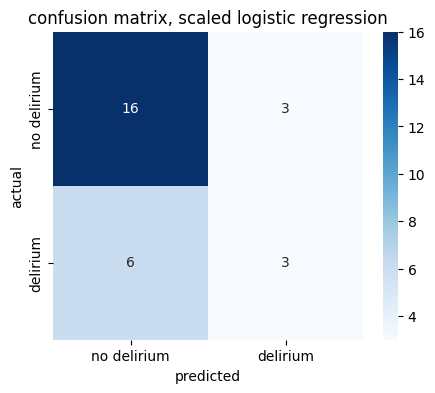

In [7]:
# confusion matrix and a few more metrics for the scaled model
cm = confusion_matrix(y_test, pred_s)
print('precision:', precision_score(y_test, pred_s))
print('recall:', recall_score(y_test, pred_s))
print('f1:', f1_score(y_test, pred_s))

plt.figure(figsize = (5, 4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', xticklabels = ['no delirium', 'delirium'], yticklabels = ['no delirium', 'delirium'])
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('confusion matrix, scaled logistic regression')
plt.show()

Recall is the weak spot here, the model only catches a third of the actual positive cases in the test set. With only 28 stays in the test split and 9 of them positive, that's 3 out of 9 caught, which is a rough place to draw conclusions from but still worth flagging since for a delirium screening tool you'd normally care a lot more about recall than precision, missing a real case is worse than a false alarm. That's something I'd want to address with class weighting or a different probability threshold once I have more data to work with.

In [8]:
# cross validated regularization strength to help with overfitting, still on the scaled features
lrcv = LogisticRegressionCV(Cs = np.logspace(-3, 3, 20), cv = 5, max_iter = 5000, scoring = 'roc_auc', random_state = 42)
lrcv.fit(X_train_s, y_train)

pred_cv = lrcv.predict(X_test_s)
proba_cv = lrcv.predict_proba(X_test_s)[:, 1]
print('best C:', lrcv.C_)
print('cv accuracy:', accuracy_score(y_test, pred_cv))
print('cv auc:', roc_auc_score(y_test, proba_cv))
pd.Series(lrcv.coef_[0], index = cols).sort_values()

best C: [0.16237767]
cv accuracy: 0.7142857142857143
cv auc: 0.8011695906432749


gcs_total_min   -0.796250
gender          -0.406957
sbp             -0.112511
heart_rate       0.016792
resp_rate        0.037699
spo2             0.164229
temp_f           0.218262
dbp              0.278146
anchor_age       0.343723
dtype: float64

C is the inverse of the regularization strength in scikit learn, so a smaller C means stronger regularization. Cross validation landed on C around 0.16, which is pulling the coefficients in noticeably compared to the plain scaled model, gcs_total_min drops from about negative 1.2 down to negative 0.8. That's the regularization doing its job, keeping any one feature from dominating the model just because it happened to separate the training data well, which matters a lot in a dataset this small where a handful of points can swing a coefficient around. The cross validated version also edged the auc up a little further to about 0.80, so the extra regularization is actually helping generalization here, not just shrinking things for the sake of it.

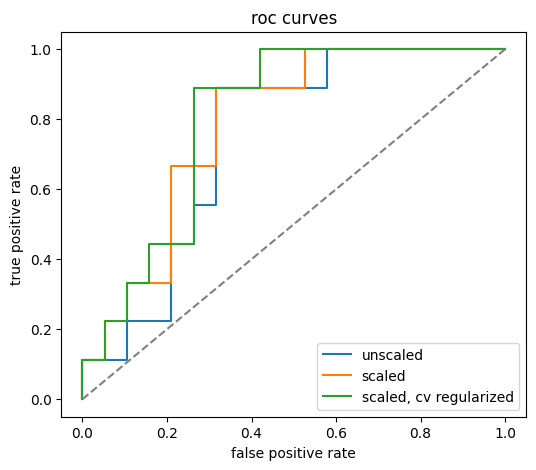

In [9]:
# roc curves for all three versions side by side
fpr_raw, tpr_raw, _ = roc_curve(y_test, raw_proba)
fpr_s, tpr_s, _ = roc_curve(y_test, proba_s)
fpr_cv, tpr_cv, _ = roc_curve(y_test, proba_cv)

plt.figure(figsize = (6, 5))
plt.plot(fpr_raw, tpr_raw, label = 'unscaled')
plt.plot(fpr_s, tpr_s, label = 'scaled')
plt.plot(fpr_cv, tpr_cv, label = 'scaled, cv regularized')
plt.plot([0, 1], [0, 1], linestyle = '--', color = 'gray')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('roc curves')
plt.legend()
plt.show()

All three curves sit well above the diagonal, so even the unscaled version that failed to converge is doing better than chance, but the scaled and regularized versions clearly pull further toward the top left corner. The main takeaway for the capstone is that feature scaling isn't just a nice to have for logistic regression, it directly affects whether the solver even converges properly, and it's a prerequisite for the coefficients to mean anything when you're trying to figure out which clinical variables actually matter most. Combined with the cross validated regularization, the scaled model also handled overfitting better than a plain unregularized fit would on a dataset this small, which is exactly the kind of thing I'll need to carry forward once I'm working with the full credentialed cohort instead of this 140 stay demo.

References

Johnson, A., Bulgarelli, L., Pollard, T., Horng, S., Celi, L. A., and Mark, R. (2023). MIMIC-IV (version 2.2). PhysioNet. https://doi.org/10.13026/6mm1-ek67

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., and Duchesnay, E. (2011). Scikit learn, machine learning in Python. Journal of Machine Learning Research, 12, 2825 to 2830. https://scikit-learn.org/stable/modules/preprocessing.html

Scikit learn developers. (n.d.). Logistic regression. Scikit learn user guide. https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression